# BANKING77: does a small model know when it is wrong?

A classifier is **calibrated** if its confidence matches its accuracy: of all answers given with 80%
confidence, 80% should be correct. This matters in practice: a calibrated small model can answer the
easy queries itself and hand the hard ones to a larger model or a human.

We compare three confidence signals (structured output, thinking off, 5 queries per intent):

| Signal | How | Extra cost |
|---|---|---|
| **stated** | the model writes `"confidence": 0-100` into its JSON answer | none |
| **token probability** | probability of the generated label, from the token log-probabilities | none |
| **sampling agreement** | ask 10 times with sampling; share of answers that agree with the greedy one | 10x |

Run the experiments with `scripts/run_calibration.py`; this notebook analyses the cached results.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import stratified_subset
from slm.evaluation.calibration import expected_calibration_error, reliability_table

CALIBRATION_DIR = RESULTS_DIR / "banking77" / "calibration"
MODELS = ["qwen3.5:2b", "qwen3.5:4b", "qwen3.5:9b"]
COLORS = {"qwen3.5:2b": "#2a78d6", "qwen3.5:4b": "#eb6834", "qwen3.5:9b": "#1baf7a"}
SIGNAL_NAMES = {"stated": "stated confidence", "label_prob": "token probability", "sampling": "sampling agreement"}
CORRECT, WRONG = "#1baf7a", "#eb6834"

dataset = load_banking77()
subset = stratified_subset(dataset.test, per_class=5)


def load(path):
    records = pd.DataFrame([json.loads(line) for line in path.read_text().splitlines()]).set_index("idx")
    return records


def signal_results(signal, model, data=subset):
    name = model.replace(":", "_")
    if signal == "sampling":
        greedy = load(RESULTS_DIR / "banking77" / "structured_no-think" / f"{name}.jsonl")
        results = data.join(greedy[["prediction"]])
        seeds = sorted((CALIBRATION_DIR / "sampling" / name).glob("seed*.jsonl"))
        votes = pd.concat([load(f).loc[data.index, "prediction"] == results["prediction"] for f in seeds], axis=1)
        results["confidence"] = votes.mean(axis=1)
    else:
        results = data.join(load(CALIBRATION_DIR / signal / f"{name}.jsonl"))
        column = {"stated": "stated_confidence", "label_prob": "label_prob"}[signal]
        results["confidence"] = results[column].fillna(0) / (100 if signal == "stated" else 1)
    results["correct"] = results["prediction"] == results["label"]
    return results

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Stated confidence: what the model says

Each model writes a confidence into its answer. If the model knew when it is wrong, wrong answers
(orange) would come with lower confidence than correct ones (green).

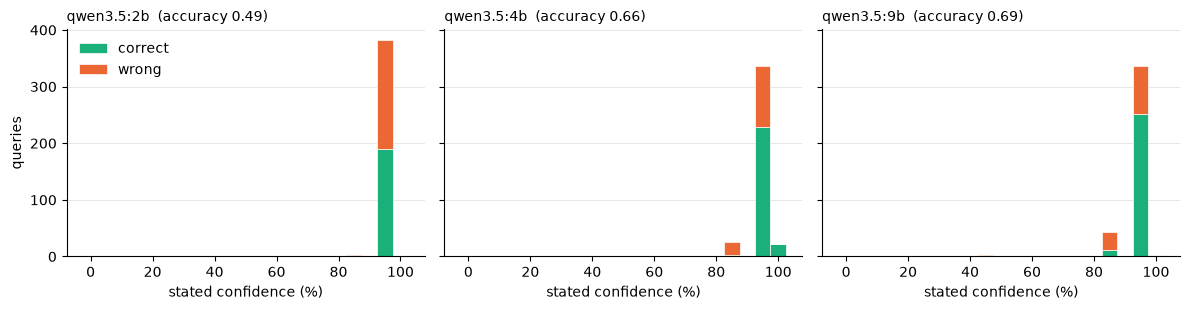

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
bins = np.arange(-2.5, 105, 5)  # one bin per multiple of 5
for ax, model in zip(axes, MODELS):
    r = signal_results("stated", model)
    ax.hist([r.loc[r["correct"], "stated_confidence"], r.loc[~r["correct"], "stated_confidence"]], bins=bins,
            stacked=True, color=[CORRECT, WRONG], label=["correct", "wrong"], edgecolor="white", linewidth=0.5)
    ax.set_title(f"{model}  (accuracy {r['correct'].mean():.2f})", loc="left", fontsize=10)
    ax.set_xlabel("stated confidence (%)")
axes[0].set_ylabel("queries")
axes[0].legend(frameon=False, loc="upper left")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
    ax.set_axisbelow(True)
plt.tight_layout()

In [3]:
pd.DataFrame({m: {"answers with 95%": (r := signal_results("stated", m))["stated_confidence"].eq(95).mean(),
                   "answers with >= 85%": r["stated_confidence"].ge(85).mean(),
                   "distinct values": r["stated_confidence"].nunique()} for m in MODELS}).round(2)

,qwen3.5:2b,qwen3.5:4b,qwen3.5:9b
answers with 95%,0.99,0.87,0.87
answers with >= 85%,1.00,0.99,0.99
distinct values,3.00,5.00,5.00


## 2. Token probability: what the model "feels"

Instead of asking, we read the probability the model assigned to its own answer. Ollama returns the
log-probabilities of each generated token and of the 20 most likely alternatives; for the label tokens we
renormalize over the alternatives that are allowed by the JSON schema (`slm.evaluation.calibration.label_probability`).

Same query as an example: *"How do I locate my card?"* — the model hesitates between `card_arrival` and
`card_delivery_estimate` at the token after `card`.

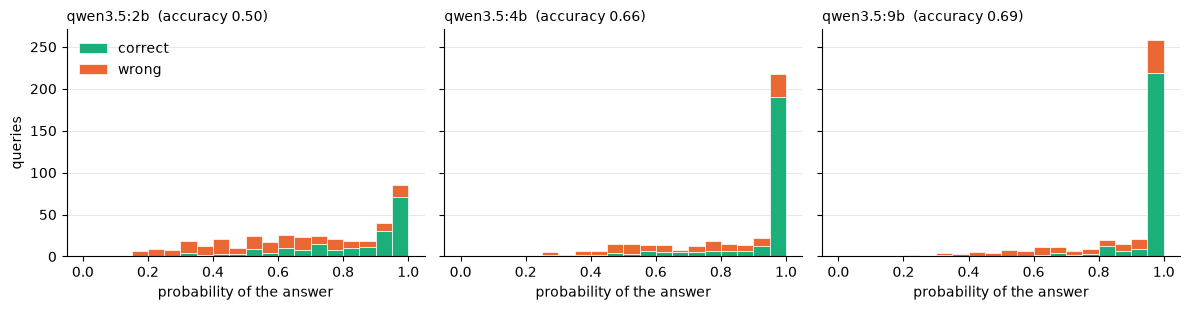

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, model in zip(axes, MODELS):
    r = signal_results("label_prob", model)
    ax.hist([r.loc[r["correct"], "confidence"], r.loc[~r["correct"], "confidence"]], bins=bins, stacked=True,
            color=[CORRECT, WRONG], label=["correct", "wrong"], edgecolor="white", linewidth=0.5)
    ax.set_title(f"{model}  (accuracy {r['correct'].mean():.2f})", loc="left", fontsize=10)
    ax.set_xlabel("probability of the answer")
axes[0].set_ylabel("queries")
axes[0].legend(frameon=False, loc="upper left")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
    ax.set_axisbelow(True)
plt.tight_layout()

## 3. Comparing the signals

Two questions:

* **Calibration (ECE)**: average gap between confidence and accuracy. Lower is better; 0 is perfect.
* **Discrimination (AUROC)**: how well confidence separates right from wrong answers, regardless of its
  scale. 0.5 = no better than chance, 1.0 = all correct answers have higher confidence than all wrong ones.

For the routing use case, discrimination is what counts: we only need a threshold that separates the two.

In [5]:
from sklearn.metrics import roc_auc_score

rows = []
for signal in SIGNAL_NAMES:
    for model in MODELS:
        if signal == "sampling" and not (CALIBRATION_DIR / "sampling" / model.replace(":", "_")).exists():
            continue
        r = signal_results(signal, model)
        rows.append({"signal": SIGNAL_NAMES[signal], "model": model, "accuracy": r["correct"].mean(),
                     "mean_confidence": r["confidence"].mean(),
                     "ece": expected_calibration_error(r["confidence"], r["correct"]),
                     "auroc": roc_auc_score(r["correct"], r["confidence"])})
comparison = pd.DataFrame(rows)
comparison.round(3)

,signal,model,accuracy,mean_confidence,ece,auroc
0,stated confidence,qwen3.5:2b,0.491,0.949,0.458,0.508
1,stated confidence,qwen3.5:4b,0.660,0.943,0.283,0.621
2,stated confidence,qwen3.5:9b,0.688,0.935,0.247,0.630
3,token probability,qwen3.5:2b,0.496,0.705,0.208,0.782
4,token probability,qwen3.5:4b,0.665,0.854,0.192,0.808
5,token probability,qwen3.5:9b,0.686,0.898,0.213,0.836
6,sampling agreement,qwen3.5:4b,0.668,0.946,0.281,0.682


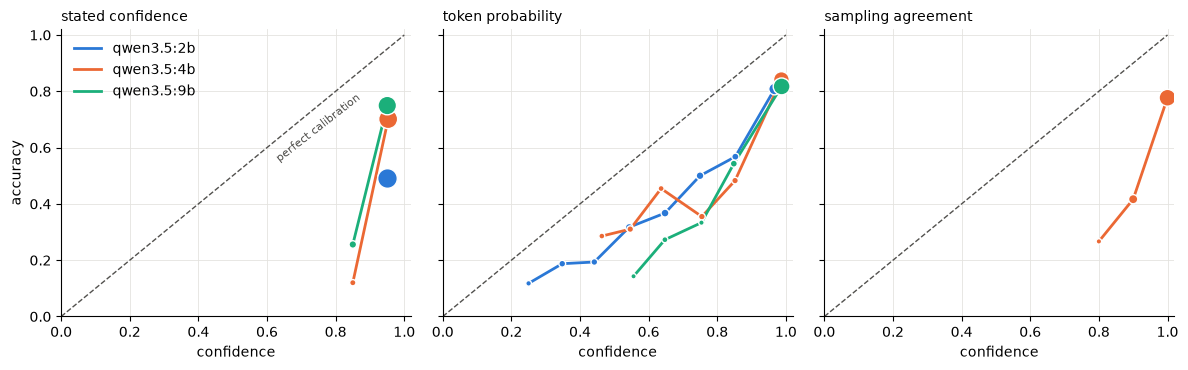

In [6]:
# Reliability diagrams: confidence vs. actual accuracy per bin (point size = number of queries;
# bins with fewer than 10 queries are left out)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, signal in zip(axes, SIGNAL_NAMES):
    ax.plot([0, 1], [0, 1], color="#52514e", linestyle="--", linewidth=1)
    for model in MODELS:
        if signal == "sampling" and not (CALIBRATION_DIR / "sampling" / model.replace(":", "_")).exists():
            continue
        r = signal_results(signal, model)
        table = reliability_table(r["confidence"], r["correct"]).query("n >= 10")
        ax.plot(table["mean_confidence"], table["accuracy"], color=COLORS[model], linewidth=2, label=model)
        ax.scatter(table["mean_confidence"], table["accuracy"], s=8 + table["n"] / 2, color=COLORS[model],
                   edgecolor="white", linewidth=1, zorder=3)
    ax.set_title(SIGNAL_NAMES[signal], loc="left", fontsize=10)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("confidence")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e4e3df", linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].set_ylabel("accuracy")
axes[0].legend(frameon=False, loc="upper left")
axes[0].annotate("perfect calibration", (0.62, 0.55), rotation=38, fontsize=8, color="#52514e")
plt.tight_layout()

## 4. What calibration buys: a cascade

`qwen3.5:4b` answers every query (full test set, 3,080 queries). If its token probability is below a threshold,
the query is passed on to `qwen3.6:35b-a3b`. Each threshold gives one point: the share of queries sent to the
large model and the resulting accuracy and cost. Latencies are those measured in notebook 01.

In [7]:
main_run = RESULTS_DIR / "banking77" / "structured_no-think"
small = dataset.test.join(load(CALIBRATION_DIR / "label_prob" / "qwen3.5_4b.jsonl")[["prediction", "label_prob"]])
small["latency_s"] = load(main_run / "qwen3.5_4b.jsonl")["latency_s"]
large = dataset.test.join(load(main_run / "qwen3.6_35b-a3b.jsonl")[["prediction", "latency_s"]])

# sanity check: same prompt and greedy decoding as notebook 01, so (nearly) the same answers
same = (small["prediction"] == load(main_run / "qwen3.5_4b.jsonl").loc[small.index, "prediction"]).mean()
print(f"answers identical to the main run: {same:.1%}")

small_correct = small["prediction"] == small["label"]
large_correct = large["prediction"] == large["label"]
confidence = small["label_prob"].fillna(0)

cascade = []
for threshold in np.unique(np.quantile(confidence, np.linspace(0, 1, 101))):
    routed = confidence < threshold
    cascade.append({
        "threshold": threshold,
        "routed": routed.mean(),
        "accuracy": np.where(routed, large_correct, small_correct).mean(),
        "latency_s": (small["latency_s"] + routed * large["latency_s"]).mean(),
    })
cascade = pd.DataFrame(cascade)

# a random router with the same share of routed queries, as a baseline
rng = np.random.default_rng(0)
random_router = [np.where(rng.random(len(small)) < share, large_correct, small_correct).mean()
                 for share in cascade["routed"]]

answers identical to the main run: 98.1%


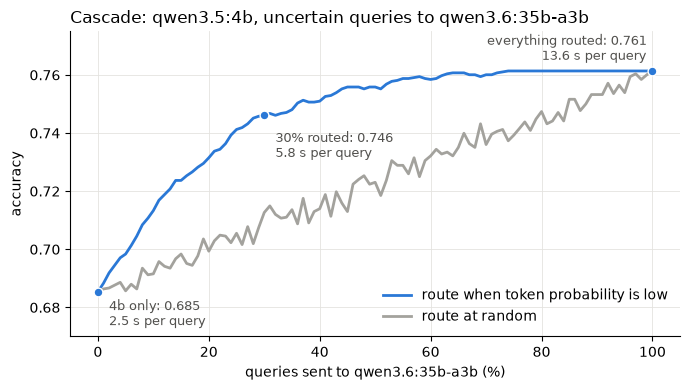

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cascade["routed"] * 100, cascade["accuracy"], color="#2a78d6", linewidth=2,
        label="route when token probability is low")
ax.plot(cascade["routed"] * 100, random_router, color="#a3a29d", linewidth=2, label="route at random")
for share, label, offset, ha in [(0, "4b only", (8, -24), "left"), (0.3, "30% routed", (8, -30), "left"),
                                 (1, "everything routed", (-4, 8), "right")]:
    point = cascade.iloc[(cascade["routed"] - share).abs().argmin()]
    ax.scatter(point["routed"] * 100, point["accuracy"], color="#2a78d6", s=40, zorder=3, edgecolor="white")
    ax.annotate(f"{label}: {point['accuracy']:.3f}\n{point['latency_s']:.1f} s per query",
                (point["routed"] * 100, point["accuracy"]), textcoords="offset points", xytext=offset, ha=ha,
                fontsize=9, color="#52514e")
ax.set_ylim(0.67, 0.775)
ax.set_xlabel("queries sent to qwen3.6:35b-a3b (%)")
ax.set_ylabel("accuracy")
ax.set_title("Cascade: qwen3.5:4b, uncertain queries to qwen3.6:35b-a3b", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()

In [9]:
# a few operating points
points = [cascade.iloc[(cascade["routed"] - share).abs().argmin()] for share in (0, 0.1, 0.2, 0.3, 0.5, 1.0)]
pd.DataFrame(points)[["threshold", "routed", "accuracy", "latency_s"]].round(3).reset_index(drop=True)

,threshold,routed,accuracy,latency_s
0,0.128,0.0,0.685,2.512
1,0.532,0.1,0.713,3.621
2,0.705,0.2,0.731,4.732
3,0.860,0.3,0.746,5.829
4,0.981,0.5,0.756,8.049
5,1.000,1.0,0.761,13.564


## Takeaways

* **Don't ask a small model how sure it is.** The stated confidence is almost a constant: `qwen3.5:2b` writes
  95% for 99% of its answers, right or wrong (AUROC 0.51 = chance). 4b and 9b are only slightly better (0.62, 0.63).
  Asking for a confidence does not change accuracy, it just adds a number without meaning.
* **The token probability is a useful signal, and it is free.** It separates right from wrong answers well
  (AUROC 0.78 / 0.81 / 0.84 for 2b / 4b / 9b) and gets better with model size. Its *scale* is overconfident:
  accuracy is about 0.2 below the mean probability for all three models, so a threshold has to be tuned on data,
  not read off as "80%".
* **Sampling agreement** (10 samples, 10x the cost) is worse than the token probability here (AUROC 0.68):
  with Qwen's recommended sampling, 4b nearly always repeats itself.
* **Calibration pays off in a cascade.** Routing the 30% least confident queries of `qwen3.5:4b` to
  `qwen3.6:35b-a3b` closes 80% of the accuracy gap (0.685 -> 0.746, vs. 0.761 for the large model alone) at about
  half the latency of the large model (5.8 s vs. 11.1 s per query). Routing at random needs far more traffic for
  the same gain.

**Caveat**: the token probability needs access to log-probabilities and, with constrained decoding, a careful
renormalization. With reasoning models (gpt-oss), the answer after the reasoning has a probability close to 1:
the uncertainty is resolved, or hidden, in the reasoning trace.